In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv("/adult_cleaned.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Rows and columns: (32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,salary
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [ ]:
# Check column names
print("Column names:")
print(df.columns.tolist())

# Check dataset information
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'salary']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_cou

salary
<=50K    24720
>50K      7841
Name: count, dtype: int64


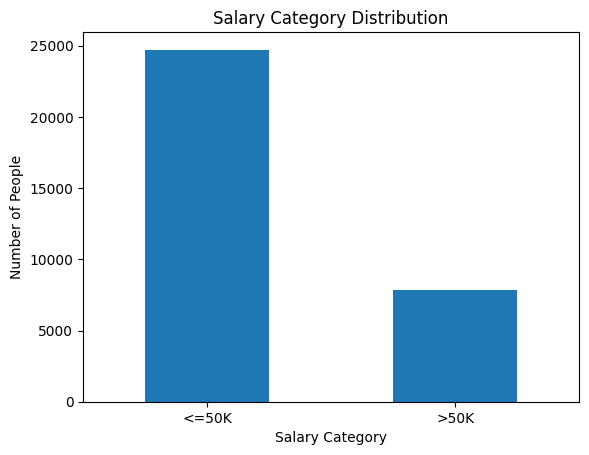

In [ ]:
salary_counts = df["salary"].value_counts()

print(salary_counts)

salary_counts.plot(
    kind="bar",
    title="Salary Category Distribution",
    xlabel="Salary Category",
    ylabel="Number of People"
)

plt.xticks(rotation=0)
plt.show()

In [ ]:
# Explore the dataset structure
print("Dataset shape:", df.shape)

# Summary statistics for numerical columns
df.describe().round(2)

Dataset shape: (32561, 15)


,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,32561.00,32561.00,32561.00,32561.00,32561.00,32561.00
mean,38.58,189778.37,10.08,1077.65,87.30,40.44
std,13.64,105549.98,2.57,7385.29,402.96,12.35
min,17.00,12285.00,1.00,0.00,0.00,1.00
25%,28.00,117827.00,9.00,0.00,0.00,40.00
50%,37.00,178356.00,10.00,0.00,0.00,40.00
75%,48.00,237051.00,12.00,0.00,0.00,45.00
max,90.00,1484705.00,16.00,99999.00,4356.00,99.00


In [ ]:
# Count unique values in each column
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

age: 73 unique values
workclass: 8 unique values
fnlwgt: 21648 unique values
education: 16 unique values
education_num: 16 unique values
marital_status: 7 unique values
occupation: 14 unique values
relationship: 6 unique values
race: 5 unique values
sex: 2 unique values
capital_gain: 119 unique values
capital_loss: 92 unique values
hours_per_week: 94 unique values
native_country: 41 unique values
salary: 2 unique values


In [ ]:
# Count people in each education and salary category

education_counts = pd.crosstab(
    df["education"],
    df["salary"]
)

education_counts

salary,<=50K,>50K
education,,
10th,871,62
11th,1115,60
12th,400,33
1st-4th,162,6
5th-6th,317,16
7th-8th,606,40
9th,487,27
Assoc-acdm,802,265
Assoc-voc,1021,361


salary,<=50K,>50K
education,,
10th,93.35,6.65
11th,94.89,5.11
12th,92.38,7.62
1st-4th,96.43,3.57
5th-6th,95.20,4.80
7th-8th,93.81,6.19
9th,94.75,5.25
Assoc-acdm,75.16,24.84
Assoc-voc,73.88,26.12


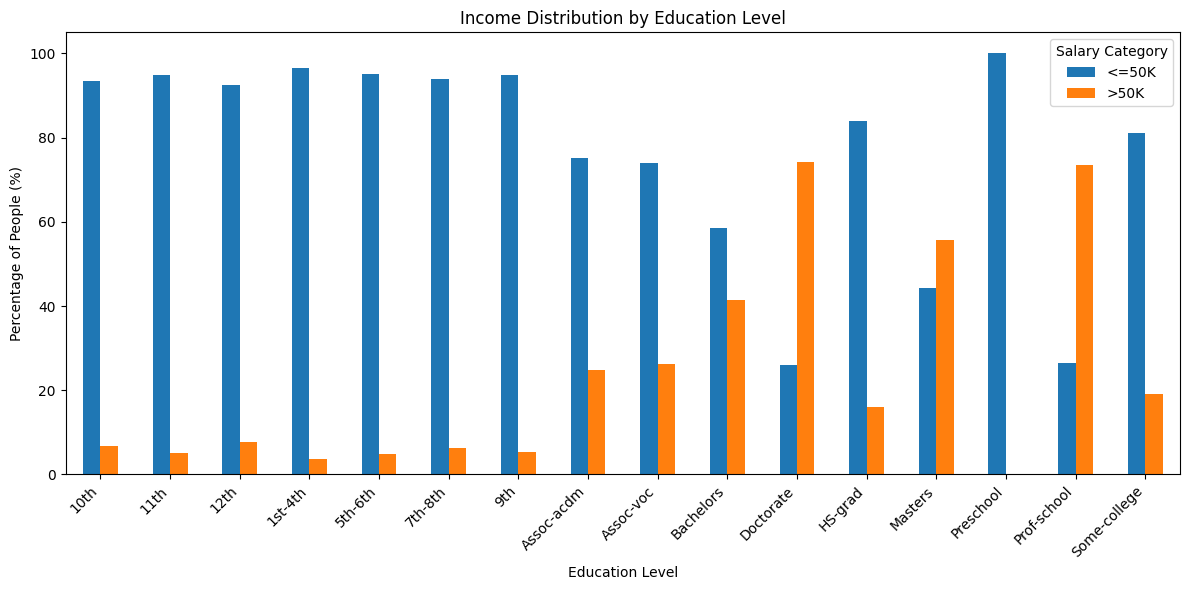

In [ ]:
# Step 1: Calculate income percentages by education
education_percentage = pd.crosstab(
    df["education"],
    df["salary"],
    normalize="index"
) * 100

education_percentage = education_percentage.round(2)

# Step 2: Display the table
display(education_percentage)

# Step 3: Create the chart
education_percentage.plot(
    kind="bar",
    figsize=(12, 6),
    title="Income Distribution by Education Level"
)

plt.xlabel("Education Level")
plt.ylabel("Percentage of People (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Salary Category")
plt.tight_layout()
plt.show()

### Insight 1: Education Level and Income Distribution

The exploratory analysis indicates an association between education level and income category in the Adult Income dataset. Records in the Doctorate and Prof-school categories have a higher proportion of individuals earning above $50,000 than records in the HS-grad category.

**Business relevance:** This pattern may help analysts understand how income distributions vary across education groups.

**Limitation:** These results show an association, not causation. Income can also be associated with occupation, age, work experience, hours worked, and other factors. The dataset is historical and US-specific.

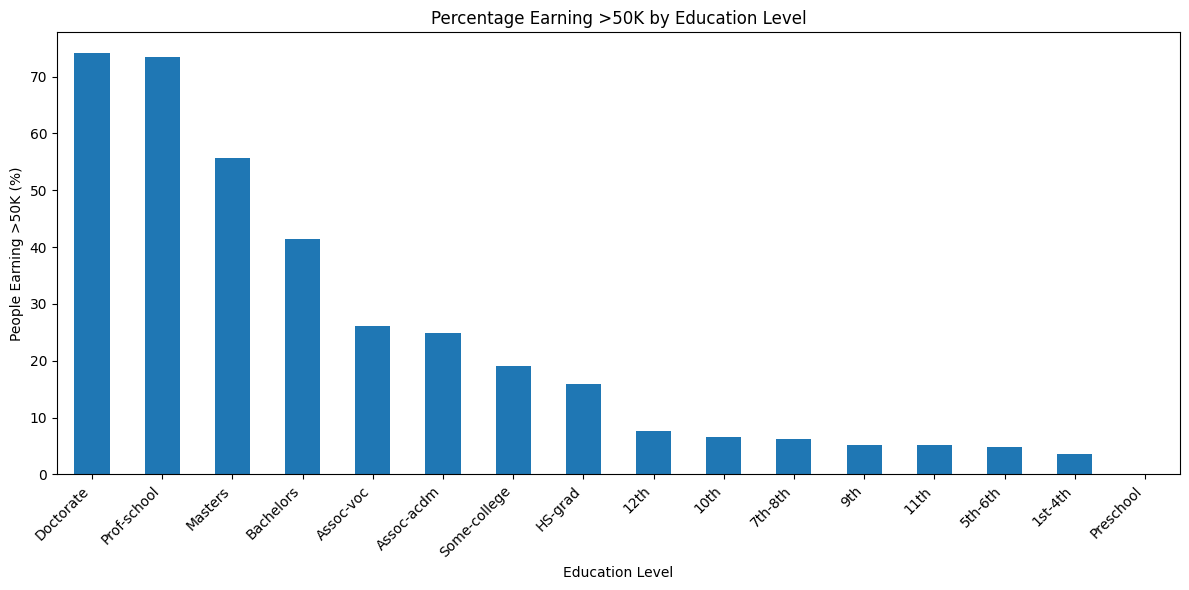

In [ ]:
# Sort education levels by the >50K percentage
education_sorted = education_percentage.sort_values(
    by=">50K",
    ascending=False
)

education_sorted.plot(
    kind="bar",
    y=">50K",
    figsize=(12, 6),
    title="Percentage Earning >50K by Education Level",
    legend=False
)

plt.xlabel("Education Level")
plt.ylabel("People Earning >50K (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
occupation_percentage = pd.crosstab(
    df["occupation"],
    df["salary"],
    normalize="index"
) * 100

occupation_percentage = occupation_percentage.round(2)

display(
    occupation_percentage.sort_values(
        by=">50K",
        ascending=False
    )
)

salary,<=50K,>50K
occupation,,
Exec-managerial,51.60,48.40
Prof-specialty,55.10,44.90
Protective-serv,67.49,32.51
Tech-support,69.50,30.50
Sales,73.07,26.93
Craft-repair,77.34,22.66
Transport-moving,79.96,20.04
Adm-clerical,86.55,13.45
Machine-op-inspct,87.51,12.49


### Insight 2: Occupation and Income Distribution

The analysis shows that income categories vary across occupations in the Adult Income dataset. Executive-managerial records have the highest proportion earning above $50,000 among the listed occupations (48.40%), followed by professional-specialty occupations (44.90%). The proportions are lower for other-service (4.16%) and private-household-service occupations (0.67%).

**Business relevance:** These differences can help analysts explore how income distributions vary by occupational group.

**Limitation:** The findings describe associations in this historical dataset. They do not establish that occupation alone determines income, and some occupations may have relatively few records.

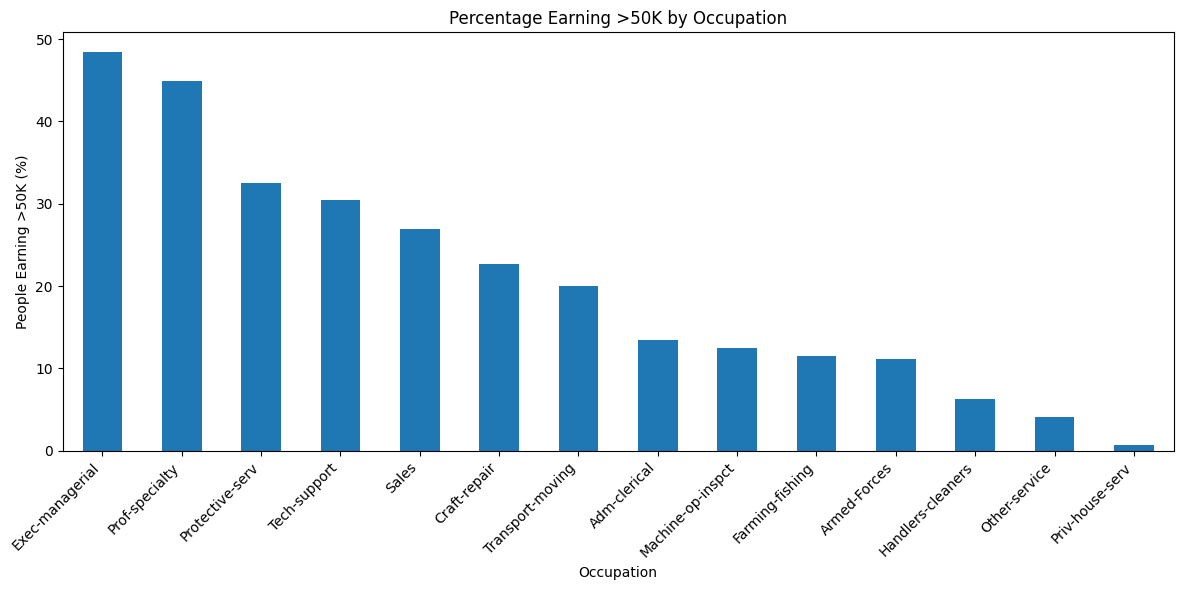

In [ ]:
occupation_sorted = occupation_percentage.sort_values(
    by=">50K",
    ascending=False
)

occupation_sorted[">50K"].plot(
    kind="bar",
    figsize=(12, 6),
    title="Percentage Earning >50K by Occupation"
)

plt.xlabel("Occupation")
plt.ylabel("People Earning >50K (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# Compare age and weekly working hours by salary category

salary_summary = df.groupby("salary")[
    ["age", "hours_per_week"]
].agg(["mean", "median", "min", "max"])

display(salary_summary.round(2))

age                hours_per_week               
         mean median min max           mean median min max
salary                                                    
<=50K   36.78   34.0  17  90          38.84   40.0   1  99
>50K    44.25   44.0  19  90          45.47   40.0   1  99

### Insight 3: Age, Working Hours, and Income

The analysis indicates that individuals in the above-$50,000 income category are older on average (44.25 years) than those in the $50,000-or-below category (36.78 years). The higher-income group also reports more average weekly working hours (45.47 compared with 38.84).

Both income groups have a median of 40 weekly working hours.

**Business relevance:** These patterns provide a starting point for examining how age and working hours relate to income distributions.

**Limitation:** These are descriptive associations, not causal relationships. Other factors, including occupation, education, and employment arrangements, may also be associated with income.

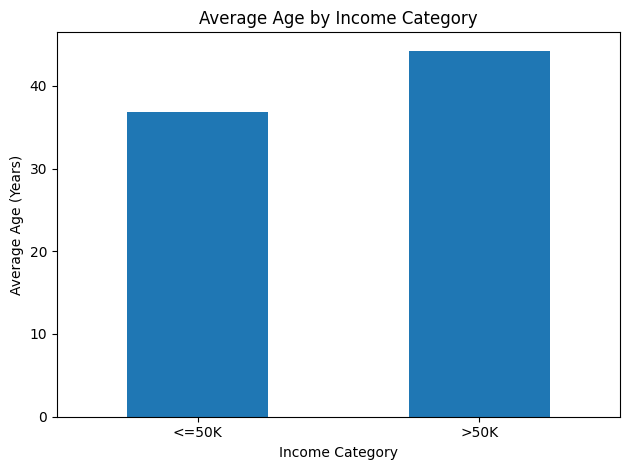

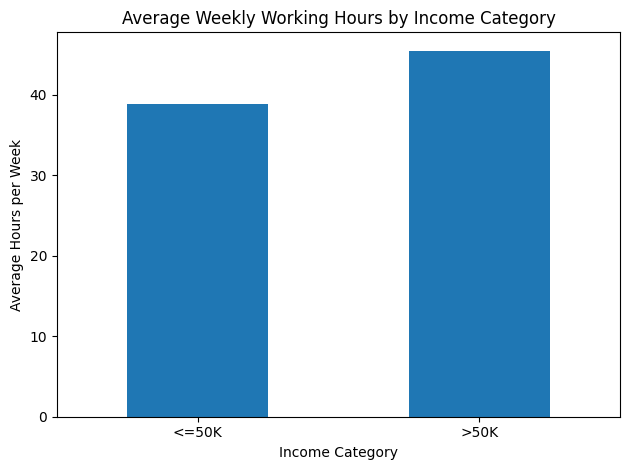

In [ ]:
# Average age by income category
df.groupby("salary")["age"].mean().plot(
    kind="bar",
    title="Average Age by Income Category",
    ylabel="Average Age (Years)",
    xlabel="Income Category",
    rot=0
)
plt.tight_layout()
plt.show()

# Average weekly hours by income category
df.groupby("salary")["hours_per_week"].mean().plot(
    kind="bar",
    title="Average Weekly Working Hours by Income Category",
    ylabel="Average Hours per Week",
    xlabel="Income Category",
    rot=0
)
plt.tight_layout()
plt.show()

In [ ]:
# Count missing values in each column
missing_summary = df.isnull().sum().sort_values(
    ascending=False
)

display(missing_summary[missing_summary > 0])

# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Check the dataset dimensions
print("Rows and columns:", df.shape)

,0
occupation,1843
workclass,1836
native_country,583


Duplicate rows: 24
Rows and columns: (32561, 15)


In [ ]:
# Display duplicate records
duplicates = df[df.duplicated(keep=False)]

print("Rows involved in duplicate groups:", len(duplicates))

display(duplicates.head(10))

Rows involved in duplicate groups: 47


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,salary
2303,90,Private,52386,Some-college,10,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,35,United-States,<=50K
3917,19,Private,251579,Some-college,10,Never-married,Other-service,Own-child,White,Male,0,0,14,United-States,<=50K
4325,25,Private,308144,Bachelors,13,Never-married,Craft-repair,Not-in-family,White,Male,0,0,40,Mexico,<=50K
4767,21,Private,250051,Some-college,10,Never-married,Prof-specialty,Own-child,White,Female,0,0,10,United-States,<=50K
4881,25,Private,308144,Bachelors,13,Never-married,Craft-repair,Not-in-family,White,Male,0,0,40,Mexico,<=50K
4940,38,Private,207202,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,48,United-States,>50K
5104,90,Private,52386,Some-college,10,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,35,United-States,<=50K
5579,27,Private,255582,HS-grad,9,Never-married,Machine-op-inspct,Not-in-family,White,Female,0,0,40,United-States,<=50K
5805,20,Private,107658,Some-college,10,Never-married,Tech-support,Not-in-family,White,Female,0,0,10,United-States,<=50K
5842,25,Private,195994,1st-4th,2,Never-married,Priv-house-serv,Not-in-family,White,Female,0,0,40,Guatemala,<=50K


### Data Quality Assessment

The dataset contains 32,561 rows and 15 columns. The initial data-quality assessment identified missing values in three columns: occupation (1,843), workclass (1,836), and native_country (583). It also identified 24 duplicate rows.

**Cleaning approach:** Missing-value placeholders were converted to proper missing values. Duplicate rows are being investigated before removal. Missing categorical values will not be replaced with assumed values without justification.

**Impact on analysis:** Missing values may affect group comparisons, while duplicate records may influence counts and percentages. These issues must be considered when preparing the final dashboard and reporting findings.

In [ ]:
# Count repeated occurrences after the first instance
print("Duplicate occurrences:", df.duplicated().sum())

# Count unique rows after removing exact duplicates
print("Rows after deduplication:", len(df.drop_duplicates()))

# Count distinct records
print("Unique rows:", len(df.drop_duplicates()))

Duplicate occurrences: 24
Rows after deduplication: 32537
Unique rows: 32537


In [ ]:
# Create a separate dataset without exact duplicate rows
df_analysis = df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Rows after removing exact duplicates:", len(df_analysis))
print("Remaining duplicates:", df_analysis.duplicated().sum())

Original rows: 32561
Rows after removing exact duplicates: 32537
Remaining duplicates: 0


In [ ]:
df_analysis.to_csv(
    "adult_analysis_ready.csv",
    index=False
)

print("Analysis dataset saved successfully!")

Analysis dataset saved successfully!


In [ ]:
import sqlite3

# Create an in-memory database
conn = sqlite3.connect(":memory:")

# Load the prepared dataset into a SQL table
df_analysis.to_sql(
    "adult_income",
    conn,
    index=False,
    if_exists="replace"
)

print("SQL database created successfully!")

SQL database created successfully!


In [ ]:
query = """
SELECT
    salary,
    COUNT(*) AS total_people
FROM adult_income
GROUP BY salary
ORDER BY total_people DESC;
"""

pd.read_sql_query(query, conn)

,salary,total_people
0,<=50K,24698
1,>50K,7839


In [ ]:
query = """
SELECT
    salary,
    COUNT(*) AS total_people,
    ROUND(
        COUNT(*) * 100.0 / (SELECT COUNT(*) FROM adult_income),
        2
    ) AS percentage
FROM adult_income
GROUP BY salary
ORDER BY total_people DESC;
"""

pd.read_sql_query(query, conn)

,salary,total_people,percentage
0,<=50K,24698,75.91
1,>50K,7839,24.09


### SQL Insight 1: Income Category Distribution

Using SQL, I analyzed 32,537 records after removing exact duplicate rows. The results show that 24,698 records (75.91%) belong to the `<=50K` income category, while 7,839 records (24.09%) belong to the `>50K` category.

**Analytical implication:** The two income categories are unevenly represented in the dataset. This should be considered when comparing groups and evaluating predictive models.

**Limitation:** These percentages describe the records in this historical dataset and should not be interpreted as current population-wide income estimates.

In [ ]:
query = """
SELECT
    education,
    COUNT(*) AS total_people,
    SUM(CASE
        WHEN salary = '>50K' THEN 1
        ELSE 0
    END) AS people_above_50k,
    ROUND(
        100.0 * SUM(CASE
            WHEN salary = '>50K' THEN 1
            ELSE 0
        END) / COUNT(*),
        2
    ) AS above_50k_percentage
FROM adult_income
GROUP BY education
ORDER BY above_50k_percentage DESC;
"""

education_sql = pd.read_sql_query(query, conn)
display(education_sql)

,education,total_people,people_above_50k,above_50k_percentage
0,Doctorate,413,306,74.09
1,Prof-school,576,423,73.44
2,Masters,1722,959,55.69
3,Bachelors,5353,2221,41.49
4,Assoc-voc,1382,361,26.12
5,Assoc-acdm,1067,265,24.84
6,Some-college,7282,1386,19.03
7,HS-grad,10494,1674,15.95
8,12th,433,33,7.62
9,10th,933,62,6.65


In [ ]:
query = """
SELECT
    occupation,
    COUNT(*) AS total_people,
    SUM(CASE
        WHEN salary = '>50K' THEN 1
        ELSE 0
    END) AS people_above_50k,
    ROUND(
        100.0 * SUM(CASE
            WHEN salary = '>50K' THEN 1
            ELSE 0
        END) / COUNT(*),
        2
    ) AS above_50k_percentage
FROM adult_income
WHERE occupation IS NOT NULL
GROUP BY occupation
ORDER BY above_50k_percentage DESC;
"""

occupation_sql = pd.read_sql_query(query, conn)
display(occupation_sql)

,occupation,total_people,people_above_50k,above_50k_percentage
0,Exec-managerial,4065,1968,48.41
1,Prof-specialty,4136,1858,44.92
2,Protective-serv,649,211,32.51
3,Tech-support,927,283,30.53
4,Sales,3650,983,26.93
5,Craft-repair,4094,929,22.69
6,Transport-moving,1597,320,20.04
7,Adm-clerical,3768,507,13.46
8,Machine-op-inspct,2000,249,12.45
9,Farming-fishing,992,115,11.59


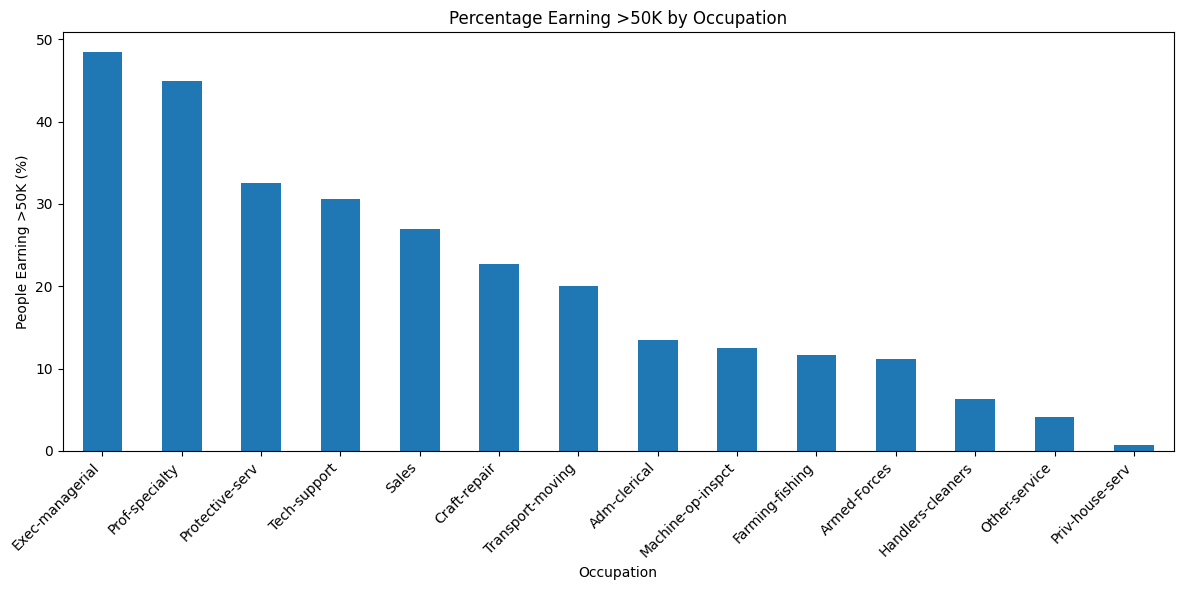

In [ ]:
occupation_sorted = occupation_sql.sort_values(
    by="above_50k_percentage",
    ascending=False
)

occupation_sorted.plot(
    kind="bar",
    x="occupation",
    y="above_50k_percentage",
    figsize=(12, 6),
    legend=False,
    title="Percentage Earning >50K by Occupation"
)

plt.xlabel("Occupation")
plt.ylabel("People Earning >50K (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Insight 4: Occupation and Income Distribution

The SQL analysis shows that the proportion of records earning above $50,000 varies by occupation. Executive-managerial occupations have the highest proportion at 48.40%, followed by professional-specialty occupations at 44.90%. Private-household-service occupations have the lowest proportion at 0.67%.

**Business relevance:** Comparing income distributions across occupations can help analysts identify differences between occupational groups and investigate potential contributing factors.

**Limitation:** These results do not establish that occupation causes a particular income level. Group sizes vary, and the data is historical and US-specific.

In [ ]:
import os

files = [
    "/content/education_income_analysis.csv",
    "/content/occupation_income_analysis.csv",
    "/content/adult_analysis_ready.csv"
]

for file in files:
    if os.path.exists(file):
        print("FOUND:", os.path.basename(file))
    else:
        print("NOT FOUND:", os.path.basename(file))

NOT FOUND: education_income_analysis.csv
NOT FOUND: occupation_income_analysis.csv
NOT FOUND: adult_analysis_ready.csv


In [ ]:
import pandas as pd
import sqlite3
import os

# Load the cleaned dataset
df = pd.read_csv("/content/adult_cleaned.csv")

# Remove exact duplicate rows for analysis
df_analysis = df.drop_duplicates().copy()

# Create SQL database
conn = sqlite3.connect(":memory:")

df_analysis.to_sql(
    "adult_income",
    conn,
    index=False,
    if_exists="replace"
)

# Education analysis
education_sql = pd.read_sql_query("""
SELECT education,
       COUNT(*) AS total_people,
       SUM(CASE WHEN salary = '>50K' THEN 1 ELSE 0 END)
           AS people_above_50k,
       ROUND(
           100.0 * SUM(CASE WHEN salary = '>50K' THEN 1 ELSE 0 END)
           / COUNT(*), 2
       ) AS above_50k_percentage
FROM adult_income
GROUP BY education
ORDER BY above_50k_percentage DESC;
""", conn)

# Occupation analysis
occupation_sql = pd.read_sql_query("""
SELECT occupation,
       COUNT(*) AS total_people,
       SUM(CASE WHEN salary = '>50K' THEN 1 ELSE 0 END)
           AS people_above_50k,
       ROUND(
           100.0 * SUM(CASE WHEN salary = '>50K' THEN 1 ELSE 0 END)
           / COUNT(*), 2
       ) AS above_50k_percentage
FROM adult_income
WHERE occupation IS NOT NULL
GROUP BY occupation
ORDER BY above_50k_percentage DESC;
""", conn)

# Export files
education_sql.to_csv(
    "/content/education_income_analysis.csv", index=False
)

occupation_sql.to_csv(
    "/content/occupation_income_analysis.csv", index=False
)

df_analysis.to_csv(
    "/content/adult_analysis_ready.csv", index=False
)

# Verify files
for name in [
    "education_income_analysis.csv",
    "occupation_income_analysis.csv",
    "adult_analysis_ready.csv"
]:
    path = "/content/" + name
    print(name, "->", "FOUND" if os.path.exists(path) else "NOT FOUND")

education_income_analysis.csv -> FOUND
occupation_income_analysis.csv -> FOUND
adult_analysis_ready.csv -> FOUND
